# Delivery_Delay_Data_Analysis


In [7]:
#import library,Load Dataset
import pandas as pd 
Delivery_data=pd.read_csv(r"D:\EXCELR OFFLINE\Python\project Delivery delay pred\DataCoSupplyChainDataset.csv",
                         encoding="ISO-8859-1")

Delivery_data.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [11]:
#Inspect data,Explore Dataset
"Rows and Columns:",Delivery_data.shape

('Rows and Columns:', (180519, 53))

In [13]:
Delivery_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [21]:
#Check Missing Values
Delivery_data.isnull().sum().sort_values(ascending=False)

Product Description              180519
Order Zipcode                    155679
Customer Lname                        8
Customer Zipcode                      3
Days for shipment (scheduled)         0
Sales per customer                    0
Benefit per order                     0
Delivery Status                       0
Late_delivery_risk                    0
Customer City                         0
Customer Country                      0
Category Id                           0
Category Name                         0
Customer Fname                        0
Customer Email                        0
Customer Password                     0
Customer Id                           0
Customer Segment                      0
Customer State                        0
Days for shipping (real)              0
Type                                  0
Department Id                         0
Customer Street                       0
Department Name                       0
Latitude                              0


In [23]:
#Check Duplicate Rows
Delivery_data.duplicated().sum()

np.int64(0)

In [25]:
#Check delivery delay distribution
Delivery_data['Late_delivery_risk'].value_counts()

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

In [30]:
#Analyze Late-Delivery Risk
Delivery_data['Late_delivery_risk'].value_counts(normalize=True).mul(100).round(2)

Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64

In [45]:
Delivery_data.groupby('Shipping Mode')['Late_delivery_risk'].mean().mul(100).round(2)

Shipping Mode
First Class       95.32
Same Day          45.74
Second Class      76.63
Standard Class    38.07
Name: Late_delivery_risk, dtype: float64

In [ ]:
#Visualize delivery risk by shipping mode


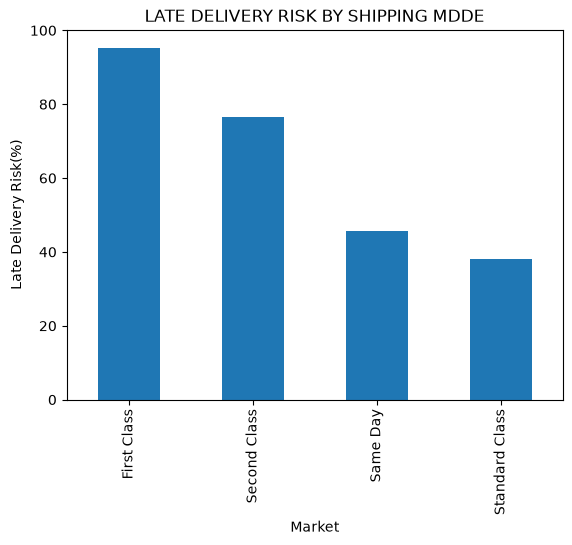

In [55]:
import matplotlib.pyplot as plt
risk=Delivery_data.groupby('Shipping Mode')['Late_delivery_risk'].mean()*100
risk = risk.sort_values(ascending=False)
risk.plot(kind='bar',title='LATE DELIVERY RISK BY SHIPPING MDDE')
plt.ylabel('Late Delivery Risk(%)')
plt.xlabel('Market')
plt.show()

Text(0.5, 0, 'Market')

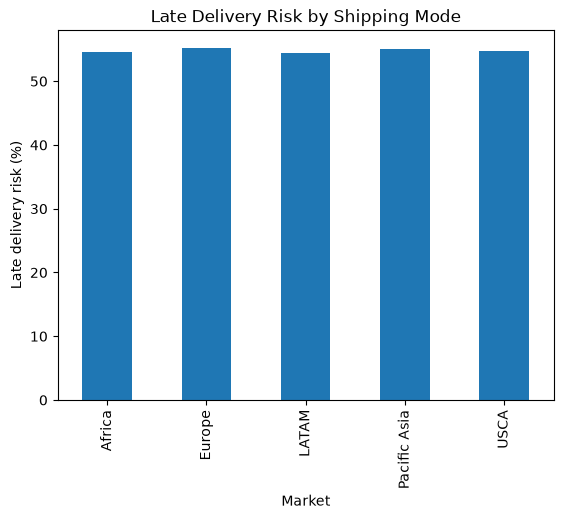

In [59]:
#Late-delivery risk by market
Risk_market=Delivery_data.groupby('Market')['Late_delivery_risk'].mean().mul(100)
Risk_market.sort_values(ascending=False)
Risk_market.plot(kind='bar',title='Late Delivery Risk by Shipping Mode')
plt.ylabel('Late delivery risk (%)')
plt.xlabel('Market')


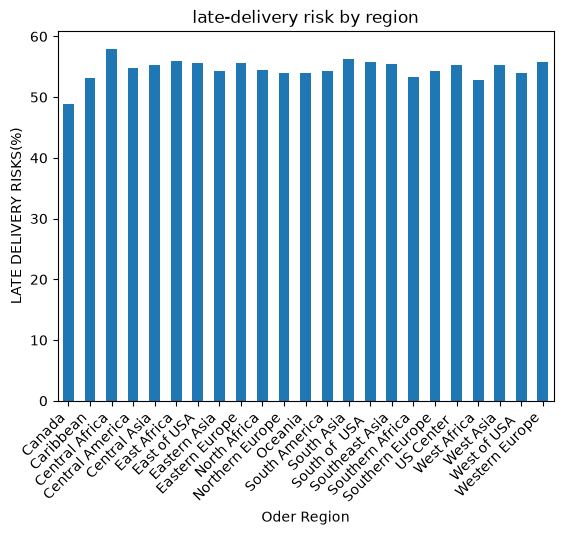

In [72]:
#Compare late-delivery risk by region
region_risk=Delivery_data.groupby('Order Region')['Late_delivery_risk'].mean().mul(100)
region_risk.sort_values(ascending=False)
region_risk.plot(kind='bar',title='late-delivery risk by region')
plt.ylabel('LATE DELIVERY RISKS(%)')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Oder Region')
plt.show()

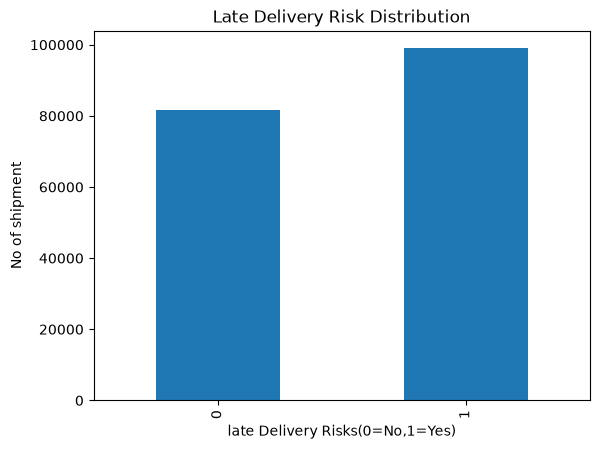

In [77]:
Delivery_data['Late_delivery_risk'].value_counts().sort_index().plot(kind='bar')
plt.ylabel('No of shipment')
plt.xlabel('late Delivery Risks(0=No,1=Yes)')
plt.title('Late Delivery Risk Distribution')
plt.show()